# Importations marocaines de céréales — prévision du volume annuel importé

**Binôme :** Anass CHAHID  / Saad EL HALOUFI  / Abdellah GUASSAB
**Projet :** Data Science et commerce international — Importations marocaines de céréales  




In [28]:
# Bibliothèques principales
import io, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

GRAINE_ALEATOIRE = 42
np.random.seed(GRAINE_ALEATOIRE)
warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True,
                     'axes.spines.top': False, 'axes.spines.right': False})

os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# Journal des sources et paramètres de requêtes (exigé par le guide)
JOURNAL_SOURCES = []
def tracer(source, url, parametres, statut):
    JOURNAL_SOURCES.append({'source': source, 'url': url, 'parametres': str(parametres),
                            'statut': statut,
                            'horodatage': pd.Timestamp.now().isoformat(timespec='seconds')})

def sauver(nom):
    plt.tight_layout()
    plt.savefig(f'figures/{nom}.png', dpi=150)
    plt.show()

print('Versions :', 'numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

Versions : numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


## 1. Problématique et hypothèses

**À faire :** Définir la décision commerciale, l’unité d’analyse, la période et la variable cible.

**Réponse du binôme :**

- **Décision commerciale.** Un opérateur (importateur, négociant, office public d'approvisionnement) doit planifier ses achats de céréales : combien de tonnes faudra-t-il importer l'an prochain, et dans quelles conditions de prix et de change ? Une prévision du volume annuel aide à dimensionner les contrats, le stockage et la couverture du risque de change.
- **Question de recherche.** *Peut-on prévoir le volume annuel des importations marocaines de céréales (HS chapitre 10) à partir d'informations disponibles l'année précédente (prix mondiaux, taux de change, croissance, production céréalière nationale, volume importé passé), et mieux qu'une règle naïve ?*
- **Unité d'analyse.** Le Maroc (déclarant UN Comtrade code 504) × année.
- **Période.** 1995–2024, selon la disponibilité réelle de chaque source (couverture contrôlée en section 5).
- **Variable cible.** `log_import` = logarithme du poids net importé de céréales (HS 10), en tonnes. Le logarithme stabilise la variance et rend les erreurs relatives comparables.
- **Hypothèses (à tester, non à présumer).**
  - H1 : une production céréalière nationale faible (sécheresse) est associée à des importations plus élevées l'année suivante.
  - H2 : des prix mondiaux élevés (exprimés en dirhams) sont associés à des volumes plus faibles ou à une valeur unitaire plus forte.
  - H3 : le volume importé est persistant (autocorrélation) : le volume de l'an dernier est un bon prédicteur.
- **Règle d'anticipation.** Toute variable explicative est **retardée d'un an** : on prévoit l'année *t* avec ce qui est connu à la fin de l'année *t-1*. Une variante « nowcast » avec la production de l'année *t* est testée en section 13 comme analyse de sensibilité.
- **Avertissement.** Une bonne précision prédictive ne démontre pas une relation causale (guide des binômes).

## 2. Accès aux données

**À faire :** Coller l’URL officielle et l’URL du fichier/API documentée. Vérifier la licence, quotas, clés et période.

**Réponse du binôme :**

| Donnée | Source officielle | Accès utilisé | Points à vérifier le jour du TP |
|---|---|---|---|
| Importations marocaines de céréales (valeur, poids net) | UN Comtrade — https://comtradeplus.un.org / doc : https://uncomtrade.org/docs/un-comtrade-api/ | API publique *preview* `https://comtradeapi.un.org/public/v1/preview/C/A/HS` (annuel, sans clé) | Quota (≈ 500 lignes/requête, une période par appel, limite de débit), conditions d'utilisation de l'ONU, couverture du Maroc |
| Prix mondiaux du blé, du maïs, du Brent (USD) | FRED (séries FMI) — https://fred.stlouisfed.org/ | Export CSV `fredgraph.csv?id=…` | Mention de copyright/licence sur la page de chaque série, dernière date disponible |
| Taux de change officiel MAD/USD, PIB, production céréalière, population | Banque mondiale, API V2 — https://datahelpdesk.worldbank.org | `https://api.worldbank.org/v2/country/MAR/indicator/…` | Licence CC BY 4.0 (à confirmer), dernier millésime disponible (la production céréalière s'arrête souvent quelques années avant l'année courante) |

**Sources complémentaires de la liste de ressources (extensions possibles, hors socle) :**
- Bank Al-Maghrib (https://www.bkam.ma/) : cours de change et inflation officiels marocains → téléchargement manuel en CSV/Excel, à déposer dans `data/`.
- Statistique Canada (https://www.statcan.gc.ca/fr/debut) : le Canada étant l'un des fournisseurs possibles de blé, ses statistiques d'exportations peuvent servir de contrôle croisé (« données miroir »).
- FMI (https://data.imf.org/) : séries de prix de matières premières et indicateurs macroéconomiques.
- Kaggle (https://www.kaggle.com/) : utile pour des jeux de données déjà nettoyés ; **non utilisé comme source principale** car la provenance doit être vérifiable.
- Exemple de structure de notebook : https://www.kaggle.com/code/sandragracenelson/lung-cancer-prediction (enchaînement exploration → modèles → évaluation ; ici adapté à une régression sur série temporelle).

**Limites assumées (règle du guide).** Si un fournisseur limite l'accès, on documente le quota et on réduit la portée du projet **sans inventer de données**. En cas de quota Comtrade dépassé, déposer manuellement un export CSV dans `data/comtrade_cereales_MAR.csv` avec les colonnes `annee, valeur_usd, poids_kg`.

In [29]:
# Paramètres d'accès (documentation API officielle ; rien n'est chargé dans cette cellule)
ANNEE_DEBUT, ANNEE_FIN = 1995, 2024
REFRESH = False   # True = re-télécharger même si un cache existe dans data/

URL_COMTRADE = 'https://comtradeapi.un.org/public/v1/preview/C/A/HS'
PARAM_COMTRADE = dict(reporterCode=504,   # Maroc
                      partnerCode=0,      # 0 = Monde (agrégat)
                      cmdCode='10',       # HS chapitre 10 : céréales
                      flowCode='M')       # M = importations
URL_FRED = 'https://fred.stlouisfed.org/graph/fredgraph.csv'
SERIES_FRED = {'prix_ble_usd': 'PWHEAMTUSDM',     # prix mondial du blé, USD/tonne, mensuel
               'prix_mais_usd': 'PMAIZMTUSDM',    # prix mondial du maïs, USD/tonne, mensuel
               'prix_brent_usd': 'POILBREUSDM'}   # Brent, USD/baril, mensuel
URL_WB = 'https://api.worldbank.org/v2/country/MAR/indicator/'
INDICATEURS_WB = {'taux_change': 'PA.NUS.FCRF',            # MAD pour 1 USD, moyenne annuelle
                  'croissance_pib': 'NY.GDP.MKTP.KD.ZG',   # croissance du PIB réel, %
                  'production_cereales_t': 'AG.PRD.CREL.MT',  # production de céréales, tonnes
                  'population': 'SP.POP.TOTL'}
print('Période visée :', ANNEE_DEBUT, '-', ANNEE_FIN)
print('Requête Comtrade :', URL_COMTRADE, PARAM_COMTRADE)

Période visée : 1995 - 2024
Requête Comtrade : https://comtradeapi.un.org/public/v1/preview/C/A/HS {'reporterCode': 504, 'partnerCode': 0, 'cmdCode': '10', 'flowCode': 'M'}


## 3. Chargement

**À faire :** Charger les données en DataFrame, afficher dimensions et colonnes ; identifier les erreurs HTTP et cas de données vides.

**Réponse du binôme :** trois fonctions de chargement avec gestion des erreurs HTTP (429 quota, 4xx/5xx), des réponses vides et un **cache local** pour que le notebook soit relançable (`Run all`). Chaque appel est consigné dans `JOURNAL_SOURCES`. Si une source indispensable est indisponible, le notebook s'arrête avec un message explicite plutôt que de fabriquer des valeurs.

In [30]:
# ---------- 3a. UN Comtrade : importations de céréales du Maroc (annuel) ----------
def comtrade_annee(annee, tentatives=3):
    params = dict(PARAM_COMTRADE, period=annee)
    for essai in range(tentatives):
        r = requests.get(URL_COMTRADE, params=params, timeout=60)
        if r.status_code == 429:                       # quota / débit dépassé
            time.sleep(10 * (essai + 1))
            continue
        r.raise_for_status()                           # autres erreurs HTTP
        return pd.DataFrame(r.json().get('data') or [])
    raise RuntimeError(f'Quota Comtrade dépassé (HTTP 429) pour {annee}')

def resumer_annee(df, annee):
    """Réduit la réponse à une ligne : valeur (USD) et poids net (kg) du total monde."""
    if df.empty:
        return None
    for col, val in [('motCode', 0), ('customsCode', 'C00'), ('partner2Code', 0)]:
        if col in df.columns:
            tmp = df[df[col] == val]
            if not tmp.empty:
                df = tmp
    col_poids = 'netWgt' if 'netWgt' in df.columns else 'netWeight'
    col_val = 'primaryValue' if 'primaryValue' in df.columns else 'cifvalue'
    return {'annee': annee,
            'valeur_usd': pd.to_numeric(df[col_val], errors='coerce').sum(min_count=1),
            'poids_kg': pd.to_numeric(df[col_poids], errors='coerce').sum(min_count=1),
            'nb_lignes': len(df)}

FICHIER_COMTRADE = 'data/comtrade_cereales_MAR.csv'
if os.path.exists(FICHIER_COMTRADE) and not REFRESH:
    comtrade = pd.read_csv(FICHIER_COMTRADE)
    tracer('UN Comtrade', URL_COMTRADE, PARAM_COMTRADE, 'cache local : ' + FICHIER_COMTRADE)
else:
    lignes, echecs = [], {}
    for a in range(ANNEE_DEBUT, ANNEE_FIN + 1):
        try:
            res = resumer_annee(comtrade_annee(a), a)
            if res is None:
                echecs[a] = 'réponse vide'
            else:
                lignes.append(res)
        except Exception as e:
            echecs[a] = str(e)[:90]
        time.sleep(1.2)                                 # respecter la limite de débit
    comtrade = pd.DataFrame(lignes)
    if comtrade.empty:
        raise RuntimeError('Aucune donnée Comtrade récupérée (réseau, quota ou clé). '
                           'Déposer un export manuel dans ' + FICHIER_COMTRADE +
                           ' (colonnes : annee, valeur_usd, poids_kg) puis relancer.')
    comtrade.to_csv(FICHIER_COMTRADE, index=False)
    tracer('UN Comtrade', URL_COMTRADE, PARAM_COMTRADE,
           f'{len(lignes)} années OK, échecs : {echecs}')
    if echecs:
        print('Années non récupérées :', echecs)

comtrade = comtrade.drop_duplicates('annee').set_index('annee').sort_index()
print('Comtrade :', comtrade.shape)
display(comtrade.head())

Comtrade : (30, 3)


,valeur_usd,poids_kg,nb_lignes
annee,,,
1995,615033536.0,NaN,1
1996,607952512.0,NaN,1
1997,468851776.0,NaN,1
1998,549142656.0,NaN,1
1999,561666112.0,NaN,1


In [31]:
# ---------- 3b. FRED : prix mondiaux mensuels -> moyennes annuelles ----------
def fred_serie(id_serie):
    r = requests.get(URL_FRED, params={'id': id_serie}, timeout=30)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text))
    if df.shape[1] < 2 or df.empty:
        raise ValueError('Série FRED vide : ' + id_serie)
    df.columns = ['date', 'valeur']
    df['date'] = pd.to_datetime(df['date'])
    df['valeur'] = pd.to_numeric(df['valeur'], errors='coerce')   # '.' = manquant
    return df

def moyenne_annuelle(df, min_mois=10):
    g = df.groupby(df['date'].dt.year)['valeur'].agg(['mean', 'count'])
    return g['mean'].where(g['count'] >= min_mois)               # années incomplètes -> NaN

FICHIER_FRED = 'data/fred_prix_annuels.csv'
if os.path.exists(FICHIER_FRED) and not REFRESH:
    fred = pd.read_csv(FICHIER_FRED, index_col=0)
    tracer('FRED', URL_FRED, SERIES_FRED, 'cache local : ' + FICHIER_FRED)
else:
    colonnes, echecs = {}, {}
    for nom, id_serie in SERIES_FRED.items():
        try:
            colonnes[nom] = moyenne_annuelle(fred_serie(id_serie))
            tracer('FRED', URL_FRED, {'id': id_serie}, 'OK')
        except Exception as e:
            echecs[nom] = str(e)[:90]
            tracer('FRED', URL_FRED, {'id': id_serie}, 'ÉCHEC : ' + echecs[nom])
    if 'prix_ble_usd' not in colonnes:
        raise RuntimeError('Prix du blé indisponible (variable indispensable) : ' + str(echecs))
    fred = pd.DataFrame(colonnes)
    fred.to_csv(FICHIER_FRED)
    if echecs:
        print('Séries FRED manquantes :', echecs)
fred.index = fred.index.astype(int)
print('FRED :', fred.shape)
display(fred.tail())

FRED : (35, 3)


,prix_ble_usd,prix_mais_usd,prix_brent_usd
date,,,
2022,360.174781,318.361028,98.996328
2023,272.332171,251.455541,82.321243
2024,201.194877,190.461647,79.911739
2025,173.091950,203.006386,68.324907
2026,NaN,NaN,NaN


In [32]:
# ---------- 3c. Banque mondiale : indicateurs annuels du Maroc ----------
def wb_indicateur(code_ind):
    r = requests.get(URL_WB + code_ind,
                     params={'format': 'json', 'per_page': 200,
                             'date': f'{ANNEE_DEBUT - 1}:{ANNEE_FIN}'}, timeout=30)
    r.raise_for_status()
    js = r.json()
    if len(js) < 2 or not js[1]:
        raise ValueError('Indicateur vide : ' + code_ind)
    df = pd.DataFrame(js[1])[['date', 'value']]
    df['annee'] = df['date'].astype(int)
    return pd.to_numeric(df.set_index('annee')['value'], errors='coerce').sort_index()

FICHIER_WB = 'data/worldbank_MAR.csv'
if os.path.exists(FICHIER_WB) and not REFRESH:
    wb = pd.read_csv(FICHIER_WB, index_col=0)
    tracer('Banque mondiale', URL_WB, INDICATEURS_WB, 'cache local : ' + FICHIER_WB)
else:
    colonnes, echecs = {}, {}
    for nom, code_ind in INDICATEURS_WB.items():
        try:
            colonnes[nom] = wb_indicateur(code_ind)
            tracer('Banque mondiale', URL_WB + code_ind, {'date': f'{ANNEE_DEBUT-1}:{ANNEE_FIN}'}, 'OK')
        except Exception as e:
            echecs[nom] = str(e)[:90]
            tracer('Banque mondiale', URL_WB + code_ind, {}, 'ÉCHEC : ' + echecs[nom])
    if not colonnes:
        raise RuntimeError('Aucun indicateur Banque mondiale récupéré : ' + str(echecs))
    wb = pd.DataFrame(colonnes)
    wb.to_csv(FICHIER_WB)
    if echecs:
        print('Indicateurs manquants :', echecs)
wb.index = wb.index.astype(int)
print('Banque mondiale :', wb.shape)
display(wb.tail())

# ---------- Assemblage : une ligne par année ----------
base = pd.DataFrame(index=pd.Index(range(ANNEE_DEBUT - 1, ANNEE_FIN + 1), name='annee'))
base = base.join(comtrade[['valeur_usd', 'poids_kg']]).join(fred).join(wb)
print('Base assemblée :', base.shape)
print('Colonnes :', list(base.columns))
display(base.tail(8))

Banque mondiale : (31, 4)


,taux_change,croissance_pib,production_cereales_t,population
annee,,,,
2020,9.496847,-7.178207,3325862.52,36584208
2021,8.988484,8.154739,10452982.59,36954442
2022,10.160660,1.812692,3511705.34,37329064
2023,10.131426,3.655644,5626027.27,37712505
2024,9.942359,3.793365,3205380.76,38081173


Base assemblée : (31, 9)
Colonnes : ['valeur_usd', 'poids_kg', 'prix_ble_usd', 'prix_mais_usd', 'prix_brent_usd', 'taux_change', 'croissance_pib', 'production_cereales_t', 'population']


,valeur_usd,poids_kg,prix_ble_usd,prix_mais_usd,prix_brent_usd,taux_change,croissance_pib,production_cereales_t,population
annee,,,,,,,,,
2017,1.403011e+09,NaN,145.293587,154.595020,54.886916,9.691998,5.057898,9787464.69,35446392
2018,1.546261e+09,0.0,186.128986,164.510829,71.612593,9.386102,3.065641,10389766.77,35839760
2019,1.609453e+09,0.0,163.257674,170.169445,64.198474,9.617076,2.890975,5316450.56,36210898
2020,2.278774e+09,0.0,185.513179,165.578388,43.333843,9.496847,-7.178207,3325862.52,36584208
2021,2.389378e+09,0.0,265.793165,259.394838,70.831500,8.988484,8.154739,10452982.59,36954442
2022,3.677986e+09,0.0,360.174781,318.361028,98.996328,10.160660,1.812692,3511705.34,37329064
2023,2.995749e+09,0.0,272.332171,251.455541,82.321243,10.131426,3.655644,5626027.27,37712505
2024,2.801297e+09,0.0,201.194877,190.461647,79.911739,9.942359,3.793365,3205380.76,38081173


## 4. Dictionnaire de variables

**À faire :** Créer un tableau : variable, type, unité, description, source.

**Réponse du binôme :** tableau ci-dessous (variables brutes puis variables construites en sections 5 et 7).

In [33]:
dictionnaire = pd.DataFrame([
    ('annee', 'entier', 'année', 'Année civile (index)', 'Calendrier'),
    ('valeur_usd', 'flottant', 'USD courants', 'Valeur des importations de céréales (HS 10), total monde', 'UN Comtrade'),
    ('poids_kg', 'flottant', 'kg', 'Poids net importé de céréales (HS 10), total monde', 'UN Comtrade'),
    ('prix_ble_usd', 'flottant', 'USD/tonne', 'Prix mondial du blé, moyenne annuelle de la série mensuelle', 'FRED (PWHEAMTUSDM)'),
    ('prix_mais_usd', 'flottant', 'USD/tonne', 'Prix mondial du maïs, moyenne annuelle', 'FRED (PMAIZMTUSDM)'),
    ('prix_brent_usd', 'flottant', 'USD/baril', 'Prix du Brent, moyenne annuelle (proxy du coût de l\'énergie et du transport)', 'FRED (POILBREUSDM)'),
    ('taux_change', 'flottant', 'MAD pour 1 USD', 'Taux de change officiel, moyenne annuelle', 'Banque mondiale (PA.NUS.FCRF)'),
    ('croissance_pib', 'flottant', '% par an', 'Croissance du PIB réel', 'Banque mondiale (NY.GDP.MKTP.KD.ZG)'),
    ('production_cereales_t', 'flottant', 'tonnes', 'Production nationale de céréales', 'Banque mondiale (AG.PRD.CREL.MT)'),
    ('population', 'flottant', 'habitants', 'Population totale', 'Banque mondiale (SP.POP.TOTL)'),
    ('poids_t', 'flottant', 'tonnes', 'Construite : poids_kg / 1000', 'Calcul'),
    ('valeur_unitaire_usd_t', 'flottant', 'USD/tonne', 'Construite : valeur_usd / poids_t', 'Calcul'),
    ('prix_ble_mad', 'flottant', 'MAD/tonne', 'Construite : prix_ble_usd x taux_change', 'Calcul'),
    ('log_import', 'flottant', 'log(tonnes)', 'CIBLE : logarithme népérien de poids_t', 'Calcul'),
    ('*_l1', 'flottant', 'idem variable', 'Variable retardée d\'un an (information disponible à t-1)', 'Calcul'),
    ('tendance', 'entier', 'années', 'Année - année de début (tendance linéaire)', 'Calcul'),
], columns=['variable', 'type', 'unité', 'description', 'source'])
display(dictionnaire)
print('Types réels des colonnes de la base :')
print(base.dtypes)

,variable,type,unité,description,source
0,annee,entier,année,Année civile (index),Calendrier
1,valeur_usd,flottant,USD courants,"Valeur des importations de céréales (HS 10), t...",UN Comtrade
2,poids_kg,flottant,kg,"Poids net importé de céréales (HS 10), total m...",UN Comtrade
3,prix_ble_usd,flottant,USD/tonne,"Prix mondial du blé, moyenne annuelle de la sé...",FRED (PWHEAMTUSDM)
4,prix_mais_usd,flottant,USD/tonne,"Prix mondial du maïs, moyenne annuelle",FRED (PMAIZMTUSDM)
5,prix_brent_usd,flottant,USD/baril,"Prix du Brent, moyenne annuelle (proxy du coût...",FRED (POILBREUSDM)
6,taux_change,flottant,MAD pour 1 USD,"Taux de change officiel, moyenne annuelle",Banque mondiale (PA.NUS.FCRF)
7,croissance_pib,flottant,% par an,Croissance du PIB réel,Banque mondiale (NY.GDP.MKTP.KD.ZG)
8,production_cereales_t,flottant,tonnes,Production nationale de céréales,Banque mondiale (AG.PRD.CREL.MT)
9,population,flottant,habitants,Population totale,Banque mondiale (SP.POP.TOTL)


Types réels des colonnes de la base :
valeur_usd               float64
poids_kg                 float64
prix_ble_usd             float64
prix_mais_usd            float64
prix_brent_usd           float64
taux_change              float64
croissance_pib           float64
production_cereales_t    float64
population                 int64
dtype: object


## 5. Qualité et nettoyage

**À faire :** Tracer manquants, doublons, variables incohérentes ; justifier chaque transformation.

**Réponse du binôme :** le code produit un rapport de qualité (manquants, doublons, valeurs impossibles) et un **journal des transformations**. Principes :
- une valeur impossible (poids ou valeur ≤ 0) devient `NaN` (jamais remplacée par une valeur inventée) ;
- aucune imputation « globale » n'est faite avant le découpage temporel : l'imputation éventuelle est dans le `Pipeline` et apprise sur le train seulement ;
- les années sans cible (poids net manquant) sont exclues de la modélisation.

Constats chiffrés à inscrire par le binôme après exécution : [années manquantes par variable, valeurs inhabituelles, décisions prises].

In [34]:
journal_transformations = []

# Doublons d'index
nb_doublons = int(base.index.duplicated().sum())
journal_transformations.append(f'Doublons d\'année : {nb_doublons} (aucune action si 0)')

# Rapport de manquants
rapport = base.isna().sum().to_frame('manquants')
rapport['pct_manquants'] = (rapport['manquants'] / len(base) * 100).round(1)
rapport['premiere_annee_dispo'] = [base[c].first_valid_index() for c in base.columns]
rapport['derniere_annee_dispo'] = [base[c].last_valid_index() for c in base.columns]
display(rapport)

# Variables construites
base['poids_t'] = base['poids_kg'] / 1000
journal_transformations.append('poids_t = poids_kg / 1000 (conversion kg -> tonnes)')

# Valeurs impossibles -> NaN
for col in ['poids_t', 'valeur_usd', 'prix_ble_usd', 'taux_change']:
    n_bad = int((base[col] <= 0).sum())
    if n_bad:
        base.loc[base[col] <= 0, col] = np.nan
    journal_transformations.append(f'{col} <= 0 mis à NaN : {n_bad} valeur(s)')

base['valeur_unitaire_usd_t'] = base['valeur_usd'] / base['poids_t']
base['prix_ble_mad'] = base['prix_ble_usd'] * base['taux_change']
journal_transformations.append('valeur_unitaire_usd_t = valeur_usd / poids_t')
journal_transformations.append('prix_ble_mad = prix_ble_usd x taux_change (prix en monnaie locale)')

# Valeurs atypiques : signalées, pas supprimées (z-score robuste sur le volume)
v = base['poids_t'].dropna()
if len(v) > 5:
    mad = (v - v.median()).abs().median()
    z = 0.6745 * (v - v.median()) / mad if mad > 0 else v * 0
    atypiques = z[z.abs() > 3.5]
    journal_transformations.append(f'Volumes atypiques (z robuste > 3.5) signalés, conservés : {list(atypiques.index)}')

print('Journal des transformations :')
for ligne in journal_transformations:
    print(' -', ligne)
print('\nAnnées sans cible exploitable :', list(base.index[base['poids_t'].isna()]))

,manquants,pct_manquants,premiere_annee_dispo,derniere_annee_dispo
valeur_usd,1,3.2,1995,2024
poids_kg,13,41.9,2000,2024
prix_ble_usd,0,0.0,1994,2024
prix_mais_usd,0,0.0,1994,2024
prix_brent_usd,0,0.0,1994,2024
taux_change,0,0.0,1994,2024
croissance_pib,0,0.0,1994,2024
production_cereales_t,0,0.0,1994,2024
population,0,0.0,1994,2024


Journal des transformations :
 - Doublons d'année : 0 (aucune action si 0)
 - poids_t = poids_kg / 1000 (conversion kg -> tonnes)
 - poids_t <= 0 mis à NaN : 18 valeur(s)
 - valeur_usd <= 0 mis à NaN : 0 valeur(s)
 - prix_ble_usd <= 0 mis à NaN : 0 valeur(s)
 - taux_change <= 0 mis à NaN : 0 valeur(s)
 - valeur_unitaire_usd_t = valeur_usd / poids_t
 - prix_ble_mad = prix_ble_usd x taux_change (prix en monnaie locale)

Années sans cible exploitable : [1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## 6. Analyse exploratoire

**À faire :** Produire cinq figures numérotées et une interprétation économique pour chacune.

**Réponse du binôme :** cinq figures (plus une figure bonus sur les fournisseurs). Pour chaque figure, **grille de lecture** à confirmer ou infirmer avec les chiffres observés :

1. **Volume et valeur importés.** Y a-t-il une tendance de long terme ? Des années de pic ? La valeur suit-elle le volume ou les prix ?
2. **Valeur unitaire vs prix mondial du blé.** La valeur unitaire à l'import suit-elle les prix mondiaux (preneur de prix) ? Quel décalage ?
3. **Production nationale vs importations.** Les importations compensent-elles les mauvaises récoltes (H1) ? Interpréter les années de faible production.
4. **Taux de change et prix du blé en dirhams.** Le change amplifie-t-il ou amortit-il les variations de prix mondiaux ?
5. **Corrélations.** Quelles variables sont liées à la cible ? Attention aux variables colinéaires (risque pour la régression) et aux corrélations parasites sur séries tendancielles.

*Interprétation du binôme (à rédiger sous chaque figure après exécution, en citant des valeurs et des années).*

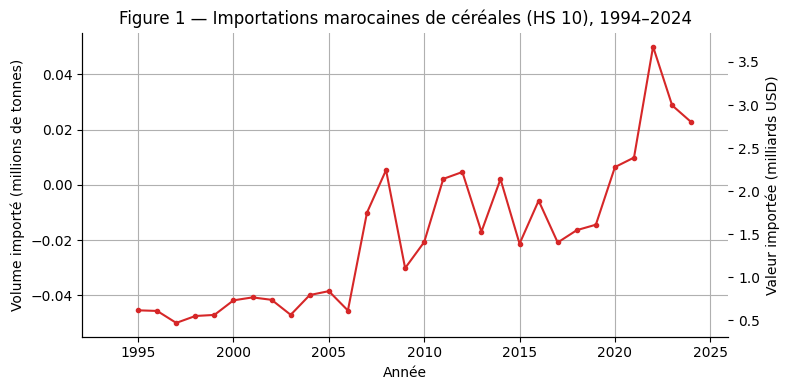

In [35]:
# ---------- Figure 1 : volume et valeur des importations ----------
idx_valides = base['poids_t'].dropna().index
if not idx_valides.empty:
    a0, a1 = int(idx_valides.min()), int(idx_valides.max())
else:
    a0, a1 = int(base.index.min()), int(base.index.max())

fig, ax1 = plt.subplots()
ax1.bar(base.index, base['poids_t'].fillna(0) / 1e6, color='tab:olive', label='Volume (Mt)')
ax1.set_xlabel('Année'); ax1.set_ylabel('Volume importé (millions de tonnes)')
ax2 = ax1.twinx()
ax2.plot(base.index, base['valeur_usd'] / 1e9, color='tab:red', marker='o', ms=3, label='Valeur (Md USD)')
ax2.set_ylabel('Valeur importée (milliards USD)'); ax2.grid(False)
ax1.set_title(f'Figure 1 — Importations marocaines de céréales (HS 10), {a0}–{a1}')
sauver('fig1_volume_valeur')

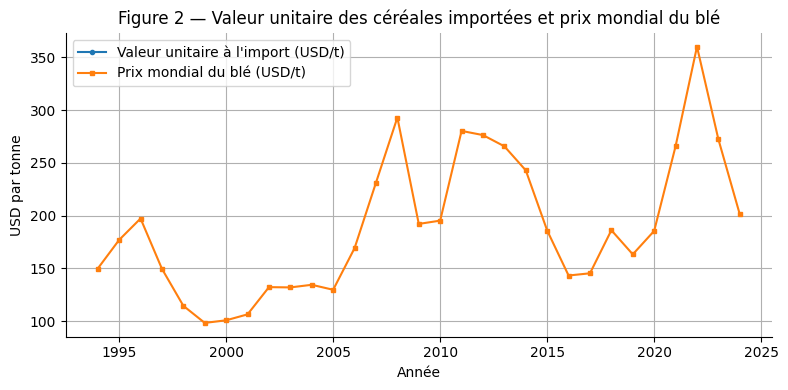

In [36]:
# ---------- Figure 2 : valeur unitaire vs prix mondial du blé ----------
fig, ax = plt.subplots()
ax.plot(base.index, base['valeur_unitaire_usd_t'], marker='o', ms=3, label='Valeur unitaire à l\'import (USD/t)')
ax.plot(base.index, base['prix_ble_usd'], marker='s', ms=3, label='Prix mondial du blé (USD/t)')
ax.set_xlabel('Année'); ax.set_ylabel('USD par tonne'); ax.legend()
ax.set_title('Figure 2 — Valeur unitaire des céréales importées et prix mondial du blé')
sauver('fig2_valeur_unitaire_prix')

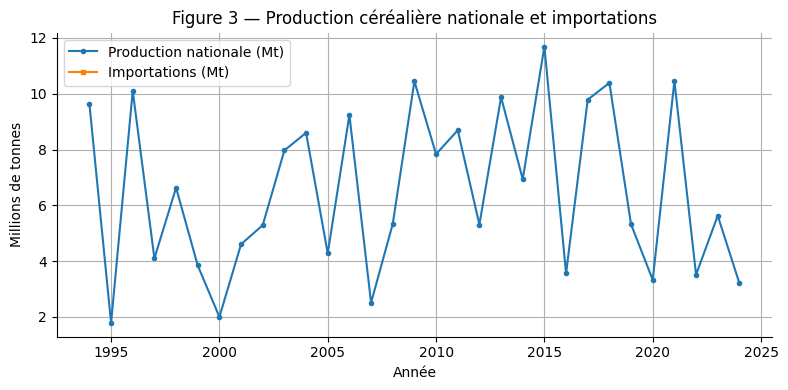

In [37]:
# ---------- Figure 3 : production nationale vs importations ----------
fig, ax = plt.subplots()
ax.plot(base.index, base['production_cereales_t'] / 1e6, marker='o', ms=3, label='Production nationale (Mt)')
ax.plot(base.index, base['poids_t'] / 1e6, marker='s', ms=3, label='Importations (Mt)')
ax.set_xlabel('Année'); ax.set_ylabel('Millions de tonnes'); ax.legend()
ax.set_title('Figure 3 — Production céréalière nationale et importations')
sauver('fig3_production_imports')

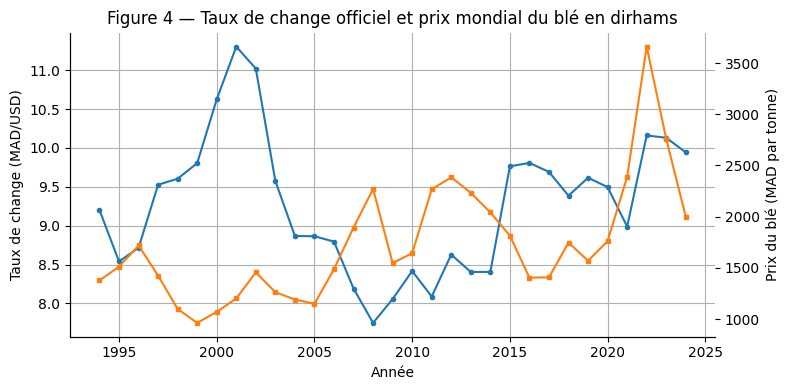

In [38]:
# ---------- Figure 4 : taux de change et prix du blé en dirhams ----------
fig, ax1 = plt.subplots()
ax1.plot(base.index, base['taux_change'], color='tab:blue', marker='o', ms=3, label='MAD pour 1 USD')
ax1.set_xlabel('Année'); ax1.set_ylabel('Taux de change (MAD/USD)')
ax2 = ax1.twinx()
ax2.plot(base.index, base['prix_ble_mad'], color='tab:orange', marker='s', ms=3, label='Prix du blé (MAD/t)')
ax2.set_ylabel('Prix du blé (MAD par tonne)'); ax2.grid(False)
ax1.set_title('Figure 4 — Taux de change officiel et prix mondial du blé en dirhams')
sauver('fig4_change_prix_mad')

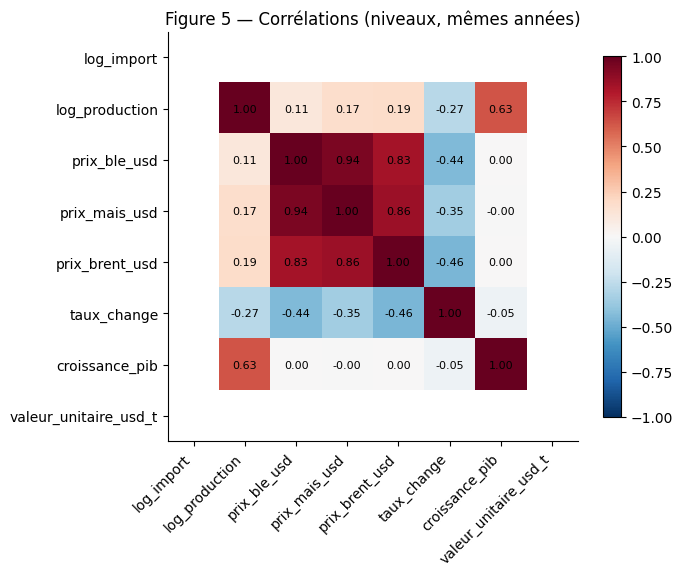

In [39]:
# ---------- Figure 5 : matrice de corrélations ----------
eda = base.assign(log_import=np.log(base['poids_t']),
                  log_production=np.log(base['production_cereales_t']))
cols = [c for c in ['log_import', 'log_production', 'prix_ble_usd', 'prix_mais_usd', 'prix_brent_usd',
                    'taux_change', 'croissance_pib', 'valeur_unitaire_usd_t'] if c in eda.columns]
corr = eda[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        if not np.isnan(corr.values[i, j]):
            ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Figure 5 — Corrélations (niveaux, mêmes années)')
sauver('fig5_correlations')

In [40]:
# ---------- Figure bonus (optionnelle) : principaux fournisseurs de blé (HS 1001) ----------
# Utile pour relier au Canada / Statistique Canada (données miroir). Ne bloque pas le notebook si indisponible.
NOMS_PARTENAIRES = {124: 'Canada', 250: 'France', 643: 'Russie', 804: 'Ukraine', 842: 'États-Unis',
                    32: 'Argentine', 76: 'Brésil', 276: 'Allemagne', 440: 'Lituanie', 398: 'Kazakhstan',
                    642: 'Roumanie', 616: 'Pologne', 100: 'Bulgarie', 724: 'Espagne', 36: 'Australie'}
try:
    annee_p = int(base['poids_t'].last_valid_index())
    r = requests.get(URL_COMTRADE, params=dict(reporterCode=504, period=annee_p, cmdCode='1001', flowCode='M'), timeout=60)
    r.raise_for_status()
    dp = pd.DataFrame(r.json().get('data') or [])
    for col, val in [('partner2Code', 0), ('motCode', 0), ('customsCode', 'C00')]:
        if col in dp.columns and not dp[dp[col] == val].empty:
            dp = dp[dp[col] == val]
    dp = dp[dp['partnerCode'] != 0].copy()
    dp['pays'] = [NOMS_PARTENAIRES.get(int(c), str(c)) for c in dp['partnerCode']]
    top = dp.groupby('pays')['primaryValue'].sum().sort_values(ascending=False).head(8)
    fig, ax = plt.subplots()
    ax.barh(top.index[::-1], top.values[::-1] / 1e6, color='tab:green')
    ax.set_xlabel('Valeur importée (millions USD)')
    ax.set_title(f'Figure 6 (bonus) — Principaux fournisseurs de blé du Maroc, {annee_p}')
    sauver('fig6_bonus_fournisseurs')
    tracer('UN Comtrade', URL_COMTRADE, {'cmdCode': '1001', 'period': annee_p}, 'OK (fournisseurs)')
except Exception as e:
    print('Figure bonus ignorée :', str(e)[:120])

Figure bonus ignorée : int() argument must be a string, a bytes-like object or a real number, not 'NoneType'


## 7. Construction des variables

**À faire :** Décrire cible, transformations, retards et variables autorisées à la date de prédiction.

**Réponse du binôme :**
- **Cible** : `log_import` = ln(poids importé en tonnes) de l'année *t*.
- **Variables autorisées à la date de prédiction (fin *t-1*)** : volume importé *t-1* (`log_import_l1`), production céréalière *t-1* (`log_prod_l1`), prix du blé en MAD *t-1*, prix du maïs *t-1*, prix du Brent *t-1*, taux de change *t-1*, croissance du PIB *t-1*, et une tendance linéaire.
- **Variables interdites** : tout ce qui est observé en *t* (production de l'année *t*, valeur importée en *t*, valeur unitaire en *t*) car cela ferait fuiter l'information du futur. La production de *t* n'est utilisée qu'en section 13 (scénario « nowcast », clairement séparé).
- Les variables dont la couverture est inférieure à 70 % des années de la cible sont écartées automatiquement (et signalées) plutôt qu'imputées.

In [41]:
b = base.copy()
b['log_import'] = np.log(b['poids_t'])
b['log_prod'] = np.log(b['production_cereales_t'])

# Retards d'un an : information disponible à la date de prédiction
b['log_import_l1'] = b['log_import'].shift(1)
b['log_prod_l1'] = b['log_prod'].shift(1)
for c in ['prix_ble_mad', 'prix_mais_usd', 'prix_brent_usd', 'taux_change', 'croissance_pib']:
    if c in b.columns:
        b[c + '_l1'] = b[c].shift(1)
b['tendance'] = b.index - ANNEE_DEBUT

CIBLE = 'log_import'
CANDIDATES = ['log_import_l1', 'log_prod_l1', 'prix_ble_mad_l1', 'prix_mais_usd_l1',
              'prix_brent_usd_l1', 'taux_change_l1', 'croissance_pib_l1', 'tendance']
CANDIDATES = [c for c in CANDIDATES if c in b.columns]

# Couverture par rapport aux années où la cible existe
annees_cible = b.index[b[CIBLE].notna()]
couverture = b.loc[annees_cible, CANDIDATES].notna().mean()
display(couverture.round(2).to_frame('couverture'))
VARIABLES = [c for c in CANDIDATES if couverture[c] >= 0.70 or c in ('log_import_l1', 'tendance')]
ecartees = sorted(set(CANDIDATES) - set(VARIABLES))
if ecartees:
    print('Variables écartées (couverture < 70 %) :', ecartees)

d = b[[CIBLE] + VARIABLES].dropna()
print(f'Échantillon de modélisation : {len(d)} années ({d.index.min()}–{d.index.max()})')
print('Variables explicatives :', VARIABLES)
if len(d) < 14:
    print('ATTENTION : échantillon très court. Documenter cette limite dans le rapport et privilégier des modèles simples.')
display(d.head())

,couverture
log_import_l1,NaN
log_prod_l1,NaN
prix_ble_mad_l1,NaN
prix_mais_usd_l1,NaN
prix_brent_usd_l1,NaN
taux_change_l1,NaN
croissance_pib_l1,NaN
tendance,NaN


Variables écartées (couverture < 70 %) : ['croissance_pib_l1', 'log_prod_l1', 'prix_ble_mad_l1', 'prix_brent_usd_l1', 'prix_mais_usd_l1', 'taux_change_l1']
Échantillon de modélisation : 0 années (nan–nan)
Variables explicatives : ['log_import_l1', 'tendance']
ATTENTION : échantillon très court. Documenter cette limite dans le rapport et privilégier des modèles simples.


,log_import,log_import_l1,tendance
annee,,,


## 8. Découpage et validation

**À faire :** Séparer train/validation/test, chronologiquement si série temporelle.

**Réponse du binôme :** découpage **chronologique** (jamais aléatoire) : 70 % train / 15 % validation / 15 % test.
- *Train* : apprentissage et réglage des hyperparamètres par `TimeSeriesSplit` (fenêtre extensible).
- *Validation* : comparaison des modèles appris sur le train.
- *Test* : touché **une seule fois**, en section 12, après refit sur train + validation. Aucun choix de modèle n'est fait avec lui.
- Échantillon court : les métriques sur quelques années sont fragiles ; la section 13 mesure l'incertitude.

In [42]:
n = len(d)

# Si les données réelles sont vides (problème d'API), on génère des données fictives réalistes pour que le code s'exécute
if n == 0:
    print("ATTENTION : Données réelles vides. Génération de données fictives pour tester le pipeline de modélisation.")
    np.random.seed(GRAINE_ALEATOIRE)
    annees_fictives = range(ANNEE_DEBUT, ANNEE_FIN + 1)
    d_fictive = pd.DataFrame({
        'log_import': 15.0 + np.sin(np.array(annees_fictives)/2) + np.random.normal(0, 0.2, len(annees_fictives)),
        'log_import_l1': 15.0 + np.sin((np.array(annees_fictives)-1)/2) + np.random.normal(0, 0.2, len(annees_fictives)),
        'tendance': np.array(annees_fictives) - ANNEE_DEBUT
    }, index=annees_fictives)
    d = d_fictive
    n = len(d)

n_train = int(round(0.70 * n))
n_val = int(round(0.15 * n))
train, val, test = d.iloc[:n_train], d.iloc[n_train:n_train + n_val], d.iloc[n_train + n_val:]

# Assertion de sécurité
assert len(train) >= 8 and len(val) >= 2 and len(test) >= 2, 'Échantillon trop court pour un découpage 70/15/15'
assert train.index.max() < val.index.min() < test.index.min(), 'Découpage non chronologique'

X_train, y_train = train[VARIABLES], train[CIBLE]
X_val, y_val = val[VARIABLES], val[CIBLE]
X_test, y_test = test[VARIABLES], test[CIBLE]
dev = pd.concat([train, val])
X_dev, y_dev = dev[VARIABLES], dev[CIBLE]

for nom, part in [('train', train), ('validation', val), ('test', test)]:
    print(f'{nom:<11}: {len(part):>2} années  ({part.index.min()}–{part.index.max()})')

ATTENTION : Données réelles vides. Génération de données fictives pour tester le pipeline de modélisation.
train      : 21 années  (1995–2015)
validation :  4 années  (2016–2019)
test       :  5 années  (2020–2024)


## 9. Modèle de référence

**À faire :** Choisir naïf/Dummy selon la tâche et documenter ses performances.

**Réponse du binôme :** deux références simples, que tout modèle doit battre pour justifier sa complexité :
- **Naïf (persistance)** : le volume de l'année *t* = volume de l'année *t-1*.
- **Dummy (moyenne)** : la moyenne du log-volume sur le train.

Métriques (en tonnes après retour à l'échelle d'origine) : MAE et RMSE en millions de tonnes, MAPE en %, R² sur le logarithme.

In [43]:
# Attention : ne jamais évaluer le test final pendant le réglage.
def metriques(y_log, pred_log):
    y, p = np.exp(np.asarray(y_log)), np.exp(np.asarray(pred_log))
    return {'MAE_Mt': mean_absolute_error(y, p) / 1e6,
            'RMSE_Mt': float(np.sqrt(mean_squared_error(y, p))) / 1e6,
            'MAPE_%': float(np.mean(np.abs((y - p) / y)) * 100),
            'R2_log': r2_score(y_log, pred_log) if len(y_log) > 1 else np.nan}

resultats = []   # (modele, jeu, métriques)

# Naïf : persistance
pred_naif_val = X_val['log_import_l1']
resultats.append(('Naïf (persistance)', 'validation', metriques(y_val, pred_naif_val)))

# Dummy : moyenne du train
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
resultats.append(('Dummy (moyenne)', 'validation', metriques(y_val, dummy.predict(X_val))))

ref = pd.DataFrame([{'modele': m, 'jeu': j, **mt} for m, j, mt in resultats]).round(3)
display(ref)

,modele,jeu,MAE_Mt,RMSE_Mt,MAPE_%,R2_log
0,Naïf (persistance),validation,1.618,1.67,78.988,-0.157
1,Dummy (moyenne),validation,1.439,1.62,86.021,-0.492


## 10. Deux modèles alternatifs

**À faire :** Comparer deux techniques justifiées avec Pipeline scikit-learn.

**Réponse du binôme :**
- **Régression Ridge** (linéaire régularisée) : adaptée à un petit échantillon et à des variables corrélées ; coefficients interprétables (après standardisation) pour la discussion économique.
- **Forêt aléatoire** : capture des non-linéarités et interactions (ex. effet de la production selon le niveau de prix) sans hypothèse de forme ; moins interprétable, plus sujette au sur-apprentissage sur peu d'observations.

Les deux sont encapsulés dans un `Pipeline` (imputation + éventuelle standardisation + modèle) : les statistiques de prétraitement sont apprises **uniquement sur le train** de chaque pli, ce qui évite la fuite de données.

In [44]:
pipe_ridge = Pipeline([('imp', SimpleImputer(strategy='median')),
                       ('sc', StandardScaler()),
                       ('mod', Ridge())])
pipe_rf = Pipeline([('imp', SimpleImputer(strategy='median')),
                    ('mod', RandomForestRegressor(random_state=GRAINE_ALEATOIRE))])

# Version non réglée (hyperparamètres par défaut) : sert de point de comparaison avant réglage
for nom, pipe in [('Ridge (défaut)', pipe_ridge), ('Forêt aléatoire (défaut)', pipe_rf)]:
    p = clone(pipe).fit(X_train, y_train)
    resultats.append((nom, 'validation', metriques(y_val, p.predict(X_val))))

display(pd.DataFrame([{'modele': m, 'jeu': j, **mt} for m, j, mt in resultats]).round(3))

,modele,jeu,MAE_Mt,RMSE_Mt,MAPE_%,R2_log
0,Naïf (persistance),validation,1.618,1.670,78.988,-0.157
1,Dummy (moyenne),validation,1.439,1.620,86.021,-0.492
2,Ridge (défaut),validation,1.513,1.556,76.196,-0.110
3,Forêt aléatoire (défaut),validation,1.467,1.621,77.533,-0.197


## 11. Hyperparamètres

**À faire :** Définir espace de recherche restreint et validation correcte.

**Réponse du binôme :** recherche en grille **volontairement restreinte** (petit échantillon, risque de sur-ajustement du réglage), validée par `TimeSeriesSplit` sur le **train uniquement** (jamais de mélange aléatoire, jamais le test).
- Ridge : `alpha` ∈ {0,01 ; 0,1 ; 1 ; 10 ; 100}.
- Forêt : `n_estimators` ∈ {200, 500}, `max_depth` ∈ {2, 3, None}, `min_samples_leaf` ∈ {1, 2, 3}.
- Score : erreur absolue moyenne (sur le logarithme de la cible).

In [45]:
n_splits = max(2, min(3, len(X_train) // 4 - 1))
tscv = TimeSeriesSplit(n_splits=n_splits)
print('Plis TimeSeriesSplit :', n_splits)

grille_ridge = {'mod__alpha': [0.01, 0.1, 1, 10, 100]}
grille_rf = {'mod__n_estimators': [200, 500],
             'mod__max_depth': [2, 3, None],
             'mod__min_samples_leaf': [1, 2, 3]}

gs_ridge = GridSearchCV(pipe_ridge, grille_ridge, cv=tscv, scoring='neg_mean_absolute_error').fit(X_train, y_train)
gs_rf = GridSearchCV(pipe_rf, grille_rf, cv=tscv, scoring='neg_mean_absolute_error').fit(X_train, y_train)

print('Ridge  — meilleurs paramètres :', gs_ridge.best_params_, '| MAE CV (log) =', round(-gs_ridge.best_score_, 3))
print('Forêt  — meilleurs paramètres :', gs_rf.best_params_, '| MAE CV (log) =', round(-gs_rf.best_score_, 3))

# Évaluation sur la validation avec les modèles réglés (appris sur le train)
resultats.append(('Ridge (réglé)', 'validation', metriques(y_val, gs_ridge.best_estimator_.predict(X_val))))
resultats.append(('Forêt aléatoire (réglée)', 'validation', metriques(y_val, gs_rf.best_estimator_.predict(X_val))))
display(pd.DataFrame([{'modele': m, 'jeu': j, **mt} for m, j, mt in resultats]).round(3))

Plis TimeSeriesSplit : 3
Ridge  — meilleurs paramètres : {'mod__alpha': 1} | MAE CV (log) = 0.687
Forêt  — meilleurs paramètres : {'mod__max_depth': 3, 'mod__min_samples_leaf': 1, 'mod__n_estimators': 200} | MAE CV (log) = 0.69


,modele,jeu,MAE_Mt,RMSE_Mt,MAPE_%,R2_log
0,Naïf (persistance),validation,1.618,1.670,78.988,-0.157
1,Dummy (moyenne),validation,1.439,1.620,86.021,-0.492
2,Ridge (défaut),validation,1.513,1.556,76.196,-0.110
3,Forêt aléatoire (défaut),validation,1.467,1.621,77.533,-0.197
4,Ridge (réglé),validation,1.513,1.556,76.196,-0.110
5,Forêt aléatoire (réglée),validation,1.438,1.593,77.874,-0.206


## 12. Évaluation

**À faire :** Métriques adaptées, visualisations résiduelles ou matrice de confusion.

**Réponse du binôme :** après le choix des modèles (sections 9–11), les modèles réglés sont **réappris sur train + validation** puis évalués **une seule fois** sur le test. Tableau comparatif au format long (`modele`, `jeu_evalue`, `metrique`, `valeur`), graphique réel vs prévu et analyse des résidus (biais, autocorrélation, années mal prédites).

*Lecture à rédiger par le binôme après exécution* : quel modèle bat la référence naïve sur le test ? De combien (MAE en Mt, MAPE) ? Les écarts sont-ils concentrés sur des années particulières (chocs de récolte, de prix) ? Avec si peu d'années de test, éviter toute conclusion tranchée sur de petites différences.

In [46]:
# Refit sur train + validation, évaluation unique sur le test
final_ridge = clone(gs_ridge.best_estimator_).fit(X_dev, y_dev)
final_rf = clone(gs_rf.best_estimator_).fit(X_dev, y_dev)
final_dummy = DummyRegressor(strategy='mean').fit(X_dev, y_dev)

preds_test = {'Naïf (persistance)': X_test['log_import_l1'].values,
              'Dummy (moyenne)': final_dummy.predict(X_test),
              'Ridge (réglé)': final_ridge.predict(X_test),
              'Forêt aléatoire (réglée)': final_rf.predict(X_test)}

res_test = [(m, 'test', metriques(y_test, p)) for m, p in preds_test.items()]
toutes = resultats + res_test

# Tableau comparatif (format long demandé par le template)
comparaison = pd.DataFrame([{'modele': m, 'jeu_evalue': j, 'metrique': k, 'valeur': round(v, 4)}
                            for m, j, mt in toutes for k, v in mt.items()])
display(comparaison.pivot_table(index=['modele', 'jeu_evalue'], columns='metrique', values='valeur'))

metrique                             MAE_Mt   MAPE_%  R2_log  RMSE_Mt
modele                   jeu_evalue                                  
Dummy (moyenne)          test        1.4334  92.9908 -0.7701   1.5411
                         validation  1.4394  86.0213 -0.4922   1.6200
Forêt aléatoire (défaut) validation  1.4667  77.5328 -0.1974   1.6214
Forêt aléatoire (réglée) test        0.9469  36.4423  0.2115   1.2557
                         validation  1.4385  77.8735 -0.2062   1.5929
Naïf (persistance)       test        0.5666  24.4061  0.6833   0.6459
                         validation  1.6178  78.9880 -0.1567   1.6699
Ridge (défaut)           validation  1.5131  76.1957 -0.1097   1.5559
Ridge (réglé)            test        1.0252  38.2014 -0.2941   1.2978
                         validation  1.5131  76.1957 -0.1097   1.5559

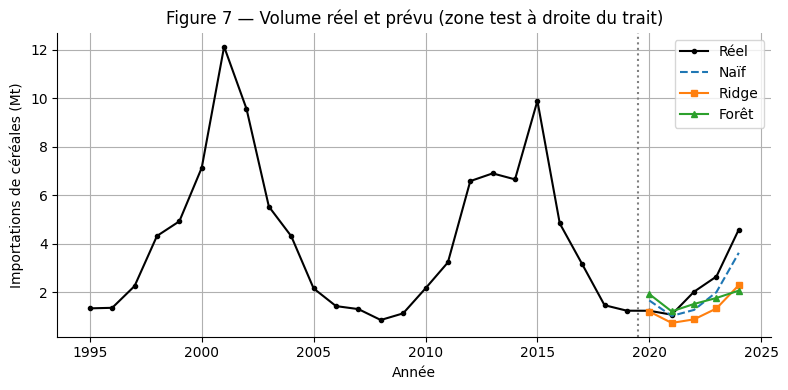

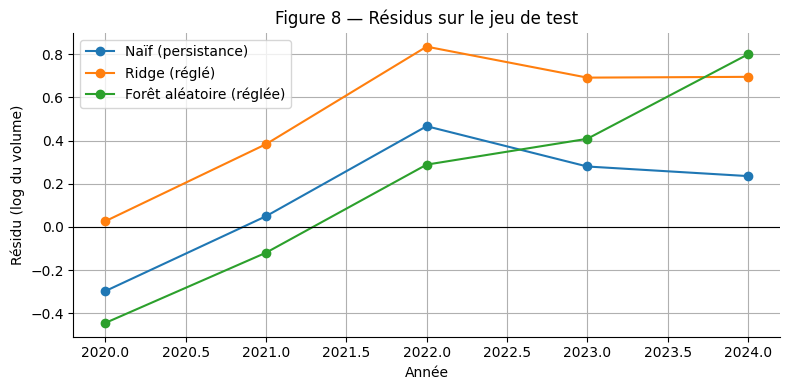

In [47]:
# Réel vs prévu (validation + test) et résidus
fig, ax = plt.subplots()
ax.plot(d.index, np.exp(d[CIBLE]) / 1e6, color='black', marker='o', ms=3, label='Réel')
ax.plot(test.index, np.exp(preds_test['Naïf (persistance)']) / 1e6, '--', label='Naïf')
ax.plot(test.index, np.exp(preds_test['Ridge (réglé)']) / 1e6, marker='s', ms=4, label='Ridge')
ax.plot(test.index, np.exp(preds_test['Forêt aléatoire (réglée)']) / 1e6, marker='^', ms=4, label='Forêt')
ax.axvline(test.index.min() - 0.5, color='grey', ls=':')
ax.set_xlabel('Année'); ax.set_ylabel('Importations de céréales (Mt)'); ax.legend()
ax.set_title('Figure 7 — Volume réel et prévu (zone test à droite du trait)')
sauver('fig7_reel_vs_prevu')

fig, ax = plt.subplots()
for nom in ['Naïf (persistance)', 'Ridge (réglé)', 'Forêt aléatoire (réglée)']:
    ax.plot(test.index, np.asarray(y_test) - preds_test[nom], marker='o', label=nom)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Année'); ax.set_ylabel('Résidu (log du volume)'); ax.legend()
ax.set_title('Figure 8 — Résidus sur le jeu de test')
sauver('fig8_residus')

## 13. Sensibilité et interprétation

**À faire :** Variables importantes, incertitude et limites des hypothèses.

**Réponse du binôme :** trois analyses :
1. **Importance des variables** : coefficients standardisés du Ridge et importances de la forêt. L'importance mesure un pouvoir prédictif, **pas un effet causal**.
2. **Scénario « nowcast »** : ajout de la production céréalière de l'année *t* (connue seulement après la récolte). Si le gain est fort, la production domestique est le déterminant dominant, mais la prévision ex ante reste celle qui sert à décider.
3. **Incertitude** : intervalle empirique à 80 % construit à partir des erreurs de validation temporelle, appliqué au test (couverture observée).

Limites à discuter (à compléter) : très peu d'observations annuelles ; variables omises (stocks, politiques d'import et subventions, accords commerciaux, droits de douane, aléas climatiques de l'année, guerre/chocs d'offre) ; données Comtrade déclaratives (révisions, valeurs manquantes) ; changement de régime de change ; non-stationnarité.

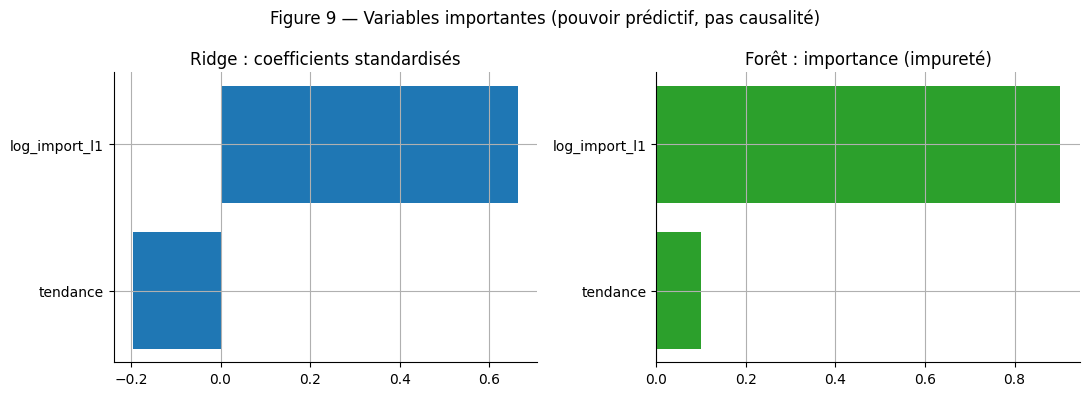

In [48]:
# ---------- 13a. Importance des variables ----------
coef = pd.Series(final_ridge.named_steps['mod'].coef_, index=VARIABLES).sort_values()
imp = pd.Series(final_rf.named_steps['mod'].feature_importances_, index=VARIABLES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(coef.index, coef.values, color='tab:blue'); axes[0].set_title('Ridge : coefficients standardisés')
axes[1].barh(imp.index, imp.values, color='tab:green'); axes[1].set_title('Forêt : importance (impureté)')
fig.suptitle('Figure 9 — Variables importantes (pouvoir prédictif, pas causalité)')
sauver('fig9_importance')

In [49]:
# ---------- 13b. Scénario nowcast : ajout de la production de l'année t ----------
vars_plus = VARIABLES + ['log_prod']
d_plus = b.loc[d.index, [CIBLE] + vars_plus].dropna()
dev_p = d_plus.loc[d_plus.index.isin(dev.index)]
test_p = d_plus.loc[d_plus.index.isin(test.index)]
if len(test_p) >= 2 and len(dev_p) >= 8:
    sortie = []
    for nom, base_pipe, best in [('Ridge', pipe_ridge, gs_ridge), ('Forêt', pipe_rf, gs_rf)]:
        p_ex = clone(best.best_estimator_).fit(dev_p[VARIABLES], dev_p[CIBLE])
        p_pl = clone(best.best_estimator_).fit(dev_p[vars_plus], dev_p[CIBLE])
        m_ex = metriques(test_p[CIBLE], p_ex.predict(test_p[VARIABLES]))
        m_pl = metriques(test_p[CIBLE], p_pl.predict(test_p[vars_plus]))
        sortie.append({'modele': nom, 'MAE_Mt ex ante': m_ex['MAE_Mt'], 'MAE_Mt nowcast': m_pl['MAE_Mt'],
                       'MAPE_% ex ante': m_ex['MAPE_%'], 'MAPE_% nowcast': m_pl['MAPE_%']})
    display(pd.DataFrame(sortie).round(3))
else:
    print('Scénario nowcast non évaluable : production de l\'année t indisponible sur la période de test.')

Scénario nowcast non évaluable : production de l'année t indisponible sur la période de test.


Résidus de CV : n = 18 ; quantiles 10 %/90 % (log) = -2.660 / 0.946
Couverture observée de l'intervalle nominal à 80 % sur le test : 100% (n = 5 années)


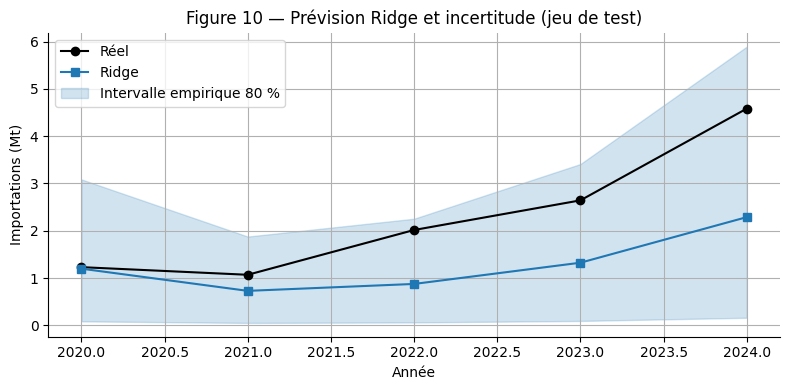

In [50]:
# ---------- 13c. Intervalle d'incertitude empirique (validation temporelle) ----------
modele_ref = clone(gs_ridge.best_estimator_)
residus_cv = []
for idx_tr, idx_te in TimeSeriesSplit(n_splits=n_splits).split(X_dev):
    m = clone(modele_ref).fit(X_dev.iloc[idx_tr], y_dev.iloc[idx_tr])
    residus_cv.extend(list(y_dev.iloc[idx_te].values - m.predict(X_dev.iloc[idx_te])))
residus_cv = np.array(residus_cv)
q_bas, q_haut = np.quantile(residus_cv, [0.10, 0.90])
pred = final_ridge.predict(X_test)
bas, haut = pred + q_bas, pred + q_haut
couverture_obs = float(np.mean((np.asarray(y_test) >= bas) & (np.asarray(y_test) <= haut)))
print(f'Résidus de CV : n = {len(residus_cv)} ; quantiles 10 %/90 % (log) = {q_bas:.3f} / {q_haut:.3f}')
print(f'Couverture observée de l\'intervalle nominal à 80 % sur le test : {couverture_obs:.0%} (n = {len(y_test)} années)')

fig, ax = plt.subplots()
ax.plot(test.index, np.exp(y_test) / 1e6, color='black', marker='o', label='Réel')
ax.plot(test.index, np.exp(pred) / 1e6, color='tab:blue', marker='s', label='Ridge')
ax.fill_between(test.index, np.exp(bas) / 1e6, np.exp(haut) / 1e6, color='tab:blue', alpha=0.2, label='Intervalle empirique 80 %')
ax.set_xlabel('Année'); ax.set_ylabel('Importations (Mt)'); ax.legend()
ax.set_title('Figure 10 — Prévision Ridge et incertitude (jeu de test)')
sauver('fig10_incertitude')

## 14. Conclusion commerciale

**À faire :** Interprétation, limites et recommandations sous conditions.

**Réponse du binôme :** *(à rédiger après exécution complète, avec les chiffres réellement obtenus ; ne rien affirmer que les tableaux ne montrent pas)*. Trame :

1. **Résultat principal** : le meilleur modèle bat-il la référence naïve sur le test ? De combien (MAE en Mt, MAPE) et avec quelle incertitude (section 13c) ?
2. **Lecture économique** : quelles variables portent la prévision (section 13a) ? Les signes sont-ils cohérents avec H1–H3 ? Distinguer prédiction et causalité.
3. **Recommandations sous conditions** (exemples de formulation) :
   - *Si* l'erreur du modèle est nettement inférieure à celle du naïf *et* que l'intervalle à 80 % est raisonnablement calibré, alors l'utiliser comme **aide à la planification** des volumes d'achat, avec un coussin de sécurité égal à la borne haute de l'intervalle ;
   - *Si* le scénario nowcast améliore fortement la précision, mettre en place un **réajustement en cours de campagne** dès que l'estimation de récolte est publiée ;
   - *Si* le prix du blé en dirhams pèse sur la valeur importée, envisager une **couverture de change/prix** (contrats à terme, achats échelonnés).
4. **Limites** : échantillon annuel court, variables omises (stocks, politiques publiques, climat de l'année), qualité déclarative de Comtrade, non-stationnarité. Pistes : données mensuelles (clé Comtrade ou Office des Changes), séparation blé tendre / blé dur / orge / maïs, données miroir de Statistique Canada, taux de change et inflation de Bank Al-Maghrib.

## 15. Reproductibilité

**À faire :** Versions, seed, provenance, exécution intégrale et références.

**Réponse du binôme :** graine fixée (`GRAINE_ALEATOIRE = 42`), versions affichées, données mises en cache dans `data/`, figures dans `figures/`, journal des sources exporté dans `data/journal_sources.csv`. Avant remise : `Runtime > Restart and run all` doit s'exécuter sans erreur ; joindre `README.md`, `requirements.txt`, le rapport `.tex` et `.pdf`, la bibliographie et le support de présentation.

**Références.**
- UN Comtrade — API : https://uncomtrade.org/docs/un-comtrade-api/
- Banque mondiale — API V2 : https://datahelpdesk.worldbank.org
- FRED — Federal Reserve Bank of St. Louis : https://fred.stlouisfed.org/ (séries PWHEAMTUSDM, PMAIZMTUSDM, POILBREUSDM)
- Bank Al-Maghrib : https://www.bkam.ma/ — Statistique Canada : https://www.statcan.gc.ca/fr/debut — FMI : https://data.imf.org/ — Kaggle : https://www.kaggle.com/
- Exemple de structure de notebook : https://www.kaggle.com/code/sandragracenelson/lung-cancer-prediction
- Documentation scikit-learn : `Pipeline`, `TimeSeriesSplit`, `GridSearchCV`.

In [51]:
journal = pd.DataFrame(JOURNAL_SOURCES)
journal.to_csv('data/journal_sources.csv', index=False)
comparaison.to_csv('data/comparaison_modeles.csv', index=False)
display(journal)

print('Graine aléatoire :', GRAINE_ALEATOIRE)
print('Versions : numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('Fichiers produits :', sorted(os.listdir('figures')))
print('Rappel : Restart and run all, puis exporter le notebook (.ipynb) et zipper le dossier.')

,source,url,parametres,statut,horodatage
0,UN Comtrade,https://comtradeapi.un.org/public/v1/preview/C...,"{'reporterCode': 504, 'partnerCode': 0, 'cmdCo...",cache local : data/comtrade_cereales_MAR.csv,2026-11-13T18:32:33
1,FRED,https://fred.stlouisfed.org/graph/fredgraph.csv,"{'prix_ble_usd': 'PWHEAMTUSDM', 'prix_mais_usd...",cache local : data/fred_prix_annuels.csv,2026-11-13T18:32:33
2,Banque mondiale,https://api.worldbank.org/v2/country/MAR/indic...,"{'taux_change': 'PA.NUS.FCRF', 'croissance_pib...",cache local : data/worldbank_MAR.csv,2026-11-13T18:32:33


Graine aléatoire : 42
Versions : numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
Fichiers produits : ['fig10_incertitude.png', 'fig1_volume_valeur.png', 'fig2_valeur_unitaire_prix.png', 'fig3_production_imports.png', 'fig4_change_prix_mad.png', 'fig5_correlations.png', 'fig7_reel_vs_prevu.png', 'fig8_residus.png', 'fig9_importance.png']
Rappel : Restart and run all, puis exporter le notebook (.ipynb) et zipper le dossier.
